# 位置を分けた LC4 と LPLC2 の閾値

LC4 と LPLC2 を、それぞれの列の位置でカメラに置き、球が近づくときと横切るときに同側の DNp01 が閾値を超えるかを見る。`lc4_motion_drive.ipynb` では LPLC2 の割合に LC4 の割合を流用していた。ここでは円に入った後シナプスを細胞種ごとに数える。

カメラは車と同じで、対角 58°、16:9、高さ 0.15 m、俯角 12° である。定数は `gf_loom_sim.ipynb` のままである。結合の本数と列の位置だけがコネクトームから来ていて、発火率と閾値はそこで選べる値である。計測にフィットしたモデルではない。見ているのは DNp01 のスパイクで、TTMn への電気シナプスはこのデータに無い。

細胞 $i$ の発火率は、円に入った自分の後シナプスの割合 $f_i$ と、球の拡大速度から決める。LC4 も LPLC2 も、この同じ式を使う。

$$
r_i = R_{\max}\,\mathrm{clip}(\dot\theta / \dot\theta_{\mathrm{sat}},\, 0,\, 1)\, f_i, \qquad
I = \frac{\sum_i w_i\, r_i / R_{\mathrm{ref}}}{W_{\mathrm{side}}}
$$

$w_i$ はその細胞から同側の DNp01 への化学シナプス数、$W_{\mathrm{side}}$ はその側の LC4 と LPLC2 の合計である。片眼の両方の細胞種が $f = 1$ で、拡大速度が 50 rad/s 以上のとき、電流は 1.6 になる。膜の平衡は電流そのものなので、電流が 1 未満のあいだはスパイクが出ない。

LPLC2 の位置は小葉板の列、LC4 は小葉の列である。画面への式はそれぞれの対応づけノートと同じで、帯ごとに上下を引き伸ばした位置は使わない。

半径 $R$、中心までの距離 $d$ の視角と拡大速度は次である。近づくとき $d$ の減少を正にする。視角が 90° になる $d = R$ で接近は止める。

$$
\theta = 2\arctan\frac{R}{d}, \qquad
\dot\theta = \frac{2 R}{d^2 + R^2}\, v_{\mathrm{close}}
$$

比べる駆動は 4 つ。

- LC4。LPLC2 は 0 のまま、拡大速度で頭打ち。
- LPLC2。LC4 は 0 のまま、同じ拡大速度。
- 両方。上の和。
- 被覆。拡大速度を使わず、円に入った細胞を 80 Hz にする。通過は拡大が小さいので、発火率の上限として置く。

同じ割合は、前のノートと同じく LPLC2 にも LC4 の $f$ を入れた比較である。


In [1]:
from pathlib import Path
import sys

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as feather

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns" / "gf-loom" / "neurons.feather").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from flycar.fov import Scene

DATA = ROOT / "data" / "malecns" / "gf-loom"
LC4_CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
LPLC2_CACHE = ROOT / "data" / "malecns" / "lplc2-camera" / "lplc2_lobula_posts.npz"
R_MAX, R_REF, THETA_DOT_SAT = 80.0, 50.0, 50.0
SCALE = R_MAX / R_REF
TAU_MS, V_THRESHOLD, REFRAC_MS = 5.0, 1.0, 5.0
DT, GEOM_DT = 0.001, 0.005
if abs(GEOM_DT / DT - round(GEOM_DT / DT)) > 1e-9:
    raise RuntimeError("幾何の刻みが膜の刻みの整数倍でない。")
REPEATS = int(round(GEOM_DT / DT))
CHUNK = 8


## 細胞とカメラ

各細胞の画面位置は、後シナプスが載る列の平均ではなく、列ごとの点を円との内外に使う。平均位置が円の外でも、樹状突起が円にかかった列の分は発火する。重みは同側の DNp01 への化学シナプス数で、電流の基準はその側の LC4 と LPLC2 の合計である。


In [2]:
def image_uv(ab, side, left_ab, right_ab):
    """u is 0 at the left edge and 1 at the right edge. v is 0 at the top."""
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code_side, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code_side
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code_side == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


def load_population(pack, keys, weight_of, side_of):
    body = pack[keys[0]]
    ab = pack[keys[1]]
    side = pack[keys[2]]
    u, v = image_uv(ab, side, pack[keys[3]], pack[keys[4]])
    order = np.argsort(body, kind="mergesort")
    body, u, v, side = body[order], u[order], v[order], side[order]
    if np.any((u < -1e-9) | (u > 1 + 1e-9) | (v < -1e-9) | (v > 1 + 1e-9)):
        raise RuntimeError("画面の外に出る後シナプスがある。")
    cuts = np.flatnonzero(np.diff(body)) + 1
    starts = np.r_[0, cuts]
    cell_n = np.diff(np.r_[starts, len(body)]).astype(np.float64)
    cell_id = body[starts]
    cell_side = side[starts]
    if np.any(np.maximum.reduceat(side, starts) != np.minimum.reduceat(side, starts)):
        raise RuntimeError("片眼に収まらない細胞がある。")
    names = side_of.loc[cell_id].to_numpy()
    expect = np.where(names == "L", np.int8(0), np.int8(1))
    if not np.array_equal(expect, cell_side):
        raise RuntimeError("画面の左右と注釈の左右が違う。")
    missing = [int(i) for i in cell_id if int(i) not in weight_of]
    if missing:
        raise RuntimeError(f"DNp01 への辺が無い細胞がある。先頭 {missing[:5]}")
    cell_w = np.array([weight_of[int(i)] for i in cell_id], dtype=np.float64)
    return {
        "u": np.ascontiguousarray(u),
        "v": np.ascontiguousarray(v),
        "starts": starts,
        "n": cell_n,
        "id": cell_id,
        "side": cell_side,
        "w": cell_w,
        "sum": np.array([cell_w[cell_side == code].sum() for code in (0, 1)]),
    }


neurons = feather.read_table(DATA / "neurons.feather").to_pandas()
edges = feather.read_table(DATA / "edges.feather").to_pandas()
gf = neurons.loc[neurons.type == "DNp01", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_post", "side": "side_post"}
)
side_of = neurons.set_index("bodyId")["side"]


def weight_onto(type_name):
    pre = neurons.loc[neurons.type == type_name, ["bodyId", "side"]].rename(
        columns={"bodyId": "body_pre", "side": "side_pre"}
    )
    part = edges.merge(pre, on="body_pre").merge(gf, on="body_post")
    if not (part.side_pre == part.side_post).all():
        raise RuntimeError(f"対側への {type_name} → DNp01 がある。")
    if not part.nt_sign.eq(1).all():
        raise RuntimeError(f"{type_name} → DNp01 にアセチルコリン以外がある。")
    return dict(zip(part.body_pre.astype(np.int64), part.weight.astype(np.float64)))


lc4 = load_population(
    np.load(LC4_CACHE),
    ("body", "ab", "side", "left_ab", "right_ab"),
    weight_onto("LC4"),
    side_of,
)
lplc = load_population(
    np.load(LPLC2_CACHE),
    ("lop_body", "lop_ab", "lop_side", "lop_left_ab", "lop_right_ab"),
    weight_onto("LPLC2"),
    side_of,
)
side_ref = lc4["sum"] + lplc["sum"]
for index, name in ((0, "左"), (1, "右")):
    lc4_i = lc4["sum"][index] / side_ref[index] * SCALE
    lplc_i = lplc["sum"][index] / side_ref[index] * SCALE
    print(
        f"{name}  LC4 {int((lc4['side'] == index).sum())} 本 {lc4['sum'][index]:.0f}"
        f"    LPLC2 {int((lplc['side'] == index).sum())} 本 {lplc['sum'][index]:.0f}"
        f"    基準 {side_ref[index]:.0f}"
        f"    全部 80 Hz の電流  LC4 {lc4_i:.3f}  LPLC2 {lplc_i:.3f}  両方 {SCALE:.3f}"
    )
if abs(lc4["sum"][0] / side_ref[0] * SCALE - 0.942) > 0.002:
    raise RuntimeError("左の LC4 だけの上限が 0.942 でない。")
if abs(lc4["sum"][1] / side_ref[1] * SCALE - 0.860) > 0.002:
    raise RuntimeError("右の LC4 だけの上限が 0.860 でない。")

scene = Scene()
hfov, vfov = scene.fovs()
pitch = float(np.deg2rad(scene.pitch_deg))
cam = np.array([0.0, 0.0, scene.cam_h])
forward = np.array([1.0, 0.0, 0.0])
left = np.array([0.0, 1.0, 0.0])
up = np.array([0.0, 0.0, 1.0])
optical = forward * np.cos(pitch) - up * np.sin(pitch)
cam_up = forward * np.sin(pitch) + up * np.cos(pitch)
cam_right = -left
tan_h = float(np.tan(hfov / 2.0))
tan_v = float(np.tan(vfov / 2.0))
print(f"水平 {np.rad2deg(hfov):.1f}°  垂直 {np.rad2deg(vfov):.1f}°")


左  LC4 71 本 3782    LPLC2 94 本 2642    基準 6424    全部 80 Hz の電流  LC4 0.942  LPLC2 0.658  両方 1.600
右  LC4 55 本 2580    LPLC2 91 本 2220    基準 4800    全部 80 Hz の電流  LC4 0.860  LPLC2 0.740  両方 1.600
水平 51.6°  垂直 30.4°


## 電流

幾何は 5 ms ごとに更新し、膜は 1 ms で積む。時定数 5 ms、閾値 1、不応期 5 ms。拡大速度が負のときは 0 にする。円が画面の外にあるフレームは、その細胞種の割合を 0 にする。


In [3]:
def covered_weight(pop, cu, cv, ru, rv, active):
    """円に入った割合を重みづけした合計。戻り値は時刻ごとの左と右。"""
    out = np.zeros((len(cu), 2), dtype=np.float64)
    idx = np.flatnonzero(active)
    syn_u, syn_v = pop["u"], pop["v"]
    starts, cell_n = pop["starts"], pop["n"]
    masks = [pop["side"] == 0, pop["side"] == 1]
    weights = [pop["w"][mask] for mask in masks]
    for start in range(0, len(idx), CHUNK):
        sel = idx[start:start + CHUNK]
        du = (syn_u[None, :] - cu[sel, None]) / ru[sel, None]
        dv = (syn_v[None, :] - cv[sel, None]) / rv[sel, None]
        inside = ((du * du + dv * dv) <= 1.0).astype(np.float64)
        frac = np.add.reduceat(inside, starts, axis=1) / cell_n
        for code_side in (0, 1):
            out[sel, code_side] = frac[:, masks[code_side]] @ weights[code_side]
    return out


def project_many(positions, radius):
    rel = positions - cam
    depth = rel @ optical
    valid = depth > 1e-4
    depth_safe = np.where(valid, depth, np.inf)
    nx = (rel @ cam_right) / depth_safe / tan_h
    ny = (rel @ cam_up) / depth_safe / tan_v
    cu = (nx + 1.0) / 2.0
    cv = (1.0 - ny) / 2.0
    ru = (radius / depth_safe) / tan_h / 2.0
    rv = (radius / depth_safe) / tan_v / 2.0
    active = (
        valid
        & (ru > 1e-8)
        & (rv > 1e-8)
        & (cu + ru >= 0.0)
        & (cu - ru <= 1.0)
        & (cv + rv >= 0.0)
        & (cv - rv <= 1.0)
    )
    return cu, cv, ru, rv, active


def expansion_many(positions, velocity, radius):
    rel = positions - cam
    dist = np.linalg.norm(rel, axis=1)
    theta = 2.0 * np.arctan(radius / dist)
    closing = -(rel @ velocity) / dist
    theta_dot = np.maximum(2.0 * radius * closing / (dist * dist + radius * radius), 0.0)
    return theta, theta_dot


def lif_count(drive):
    v = 0.0
    silent_until = 0
    refrac_steps = int(round(REFRAC_MS / (DT * 1000)))
    step = (DT * 1000) / TAU_MS
    count = 0
    voltage = np.empty(len(drive))
    for i, value in enumerate(drive):
        if i < silent_until:
            v = 0.0
            voltage[i] = 0.0
            continue
        v += step * (-v + float(value))
        if v >= V_THRESHOLD:
            voltage[i] = V_THRESHOLD
            count += 1
            v = 0.0
            silent_until = i + refrac_steps
        else:
            voltage[i] = v
    return count, voltage


def approach_path(radius, speed, offset, window=0.40):
    samples = int(round(window / GEOM_DT)) + 1
    distance = np.linspace(radius + speed * window, radius, samples)
    positions = cam + optical * distance[:, None] + left * offset
    return positions, -optical * speed


def passage_path(radius, speed, distance):
    """画像の左の外から右の外へ、光軸から distance の面を横切る。"""
    half = distance * tan_h + radius + 0.05
    samples = int(round(2.0 * half / speed / GEOM_DT)) + 1
    lateral = np.linspace(half, -half, samples)
    positions = cam + optical * distance + left * lateral[:, None]
    return positions, -left * speed


def simulate(positions, velocity, radius, keep=False):
    theta, theta_dot = expansion_many(positions, velocity, radius)
    cu, cv, ru, rv, active = project_many(positions, radius)
    w_lc4 = covered_weight(lc4, cu, cv, ru, rv, active)
    w_lplc = covered_weight(lplc, cu, cv, ru, rv, active)
    clip = np.clip(theta_dot / THETA_DOT_SAT, 0.0, 1.0)
    share_lc4 = w_lc4 / lc4["sum"]
    share_lplc = w_lplc / lplc["sum"]
    both_w = w_lc4 + w_lplc
    currents = {
        "LC4": clip[:, None] * SCALE * w_lc4 / side_ref,
        "LPLC2": clip[:, None] * SCALE * w_lplc / side_ref,
        "両方": clip[:, None] * SCALE * both_w / side_ref,
        "同じ割合": clip[:, None] * SCALE * share_lc4,
        "被覆": SCALE * both_w / side_ref,
    }
    summary = {
        "視角": float(np.rad2deg(theta.max())),
        "拡大速度": float(theta_dot.max()),
        "割合差": float(np.max(np.abs(share_lc4 - share_lplc))),
    }
    for name, array in (
        ("LC4割合", share_lc4),
        ("LPLC2割合", share_lplc),
    ):
        summary[f"{name}左"] = float(array[:, 0].max())
        summary[f"{name}右"] = float(array[:, 1].max())
    detail = None
    if keep:
        detail = {
            "geom_time": np.arange(len(theta)) * GEOM_DT,
            "time": np.arange(len(theta) * REPEATS) * DT,
            "current": currents,
            "share_lc4": share_lc4,
            "share_lplc": share_lplc,
            "voltage": {},
        }
    for name, current in currents.items():
        expanded = np.repeat(current, REPEATS, axis=0)
        left_n, left_v = lif_count(expanded[:, 0])
        right_n, right_v = lif_count(expanded[:, 1])
        summary[f"{name}電流左"] = float(current[:, 0].max())
        summary[f"{name}電流右"] = float(current[:, 1].max())
        summary[f"{name}スパイク左"] = left_n
        summary[f"{name}スパイク右"] = right_n
        if keep:
            detail["voltage"][name] = np.column_stack([left_v, right_v])
    return summary, detail


def disk_share(pop, u, v, radius):
    weight = covered_weight(
        pop,
        np.array([u]),
        np.array([v]),
        np.array([radius]),
        np.array([radius]),
        np.array([True]),
    )[0]
    return weight / pop["sum"]


still_lc4 = disk_share(lc4, 0.25, 0.50, 0.10)
still_lplc = disk_share(lplc, 0.25, 0.50, 0.10)
if abs(still_lc4[0] - 0.132) > 0.005 or still_lc4[1] != 0.0:
    raise RuntimeError(f"静止円の LC4 割合が以前と違う: {still_lc4}")
if still_lplc[1] != 0.0:
    raise RuntimeError("左の円が右の LPLC2 を刺激している。")
print(
    f"静止円 r=0.10 を左の中央  "
    f"LC4 左 {still_lc4[0]:.3f} 右 {still_lc4[1]:.3f}    "
    f"LPLC2 左 {still_lplc[0]:.3f} 右 {still_lplc[1]:.3f}"
)
still_both = SCALE * (
    still_lc4 * lc4["sum"] + still_lplc * lplc["sum"]
) / side_ref
print(f"その円を 80 Hz にした電流  左 {still_both[0]:.3f}  右 {still_both[1]:.3f}")

check, check_detail = simulate(*approach_path(0.05, 2.0, 0.0), 0.05, keep=True)
print(
    f"正面 5 cm、2 m/s  視角 {check['視角']:.1f}°  拡大速度 {check['拡大速度']:.2f}  "
    f"LC4割合 {check['LC4割合左']:.3f}  LPLC2割合 {check['LPLC2割合左']:.3f}  "
    f"両方電流 {check['両方電流左']:.3f}  同じ割合電流 {check['同じ割合電流左']:.3f}  "
    f"スパイク LC4 {check['LC4スパイク左']}  LPLC2 {check['LPLC2スパイク左']}  "
    f"両方 {check['両方スパイク左']}/{check['両方スパイク右']}"
)
if abs(check["視角"] - 90.0) > 0.1 or abs(check["拡大速度"] - 40.0) > 0.1:
    raise RuntimeError("正面 5 cm、2 m/s の視角か拡大速度が想定と違う。")
if abs(check["LC4割合左"] - 1.0) > 1e-3 or abs(check["LPLC2割合左"] - 1.0) > 1e-3:
    raise RuntimeError("接触直前に画面が両方の細胞で埋まり切っていない。")
if abs(check["両方電流左"] - 1.28) > 0.02:
    raise RuntimeError("正面 5 cm、2 m/s の両方の電流が 1.28 でない。")
if check["LC4スパイク左"] or check["LC4スパイク右"] or check["LPLC2スパイク左"] or check["LPLC2スパイク右"]:
    raise RuntimeError("片方の細胞種だけでスパイクが出た。")
if check["両方スパイク左"] < 1 or check["両方スパイク右"] < 1:
    raise RuntimeError("正面 5 cm、2 m/s で両方を入れてもスパイクが出ない。")


静止円 r=0.10 を左の中央  LC4 左 0.132 右 0.000    LPLC2 左 0.161 右 0.000
その円を 80 Hz にした電流  左 0.231  右 0.000
正面 5 cm、2 m/s  視角 90.0°  拡大速度 40.00  LC4割合 1.000  LPLC2割合 1.000  両方電流 1.280  同じ割合電流 1.280  スパイク LC4 0  LPLC2 0  両方 1/1


## 接近

球は光軸に沿って近づき、視角 90° で止める。正面はオフセット 0、左からと右からはカメラ左方向へ 0.15 m ずらす。半径は 3、5、8、12、20、40 cm。速度は 0.5、1、2、4、8 m/s。最後の 0.40 s を使う。


In [4]:
RADII = [0.03, 0.05, 0.08, 0.12, 0.20, 0.40]
SPEEDS = [0.5, 1.0, 2.0, 4.0, 8.0]
approach_rows = []
for offset, where in ((0.0, "正面"), (0.15, "左"), (-0.15, "右")):
    for radius in RADII:
        for speed in SPEEDS:
            positions, velocity = approach_path(radius, speed, offset)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"経路": where, "半径": radius, "速度": speed})
            approach_rows.append(summary)

approach = pd.DataFrame(approach_rows)
front_cols = [
    "半径", "速度", "視角", "拡大速度",
    "LC4割合左", "LPLC2割合左", "割合差",
    "LC4電流左", "LPLC2電流左", "両方電流左", "同じ割合電流左",
    "LC4スパイク左", "LPLC2スパイク左", "両方スパイク左", "両方スパイク右",
    "同じ割合スパイク左", "被覆スパイク左",
]
front = approach.loc[approach["経路"].eq("正面"), front_cols]
print("正面")
print(front.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print()
offset_view = (
    approach.loc[approach["経路"].ne("正面")]
    .groupby(["経路", "半径"], as_index=False)
    .agg(
        拡大速度=("拡大速度", "max"),
        LC4割合左=("LC4割合左", "max"),
        LPLC2割合左=("LPLC2割合左", "max"),
        LC4割合右=("LC4割合右", "max"),
        LPLC2割合右=("LPLC2割合右", "max"),
        両方電流左=("両方電流左", "max"),
        両方電流右=("両方電流右", "max"),
        両方スパイク左=("両方スパイク左", "sum"),
        両方スパイク右=("両方スパイク右", "sum"),
        被覆スパイク左=("被覆スパイク左", "sum"),
        被覆スパイク右=("被覆スパイク右", "sum"),
    )
)
print("左右に 0.15 m ずらした接近。スパイクは速度 5 通りの合計")
print(offset_view.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
presence = int(
    ((approach["両方スパイク左"] > 0) != (approach["同じ割合スパイク左"] > 0)).sum()
    + ((approach["両方スパイク右"] > 0) != (approach["同じ割合スパイク右"] > 0)).sum()
)
count_diff = int(
    (approach["両方スパイク左"] != approach["同じ割合スパイク左"]).sum()
    + (approach["両方スパイク右"] != approach["同じ割合スパイク右"]).sum()
)
print(
    "LC4 だけのスパイク合計",
    int(approach["LC4スパイク左"].sum() + approach["LC4スパイク右"].sum()),
    "   LPLC2 だけ",
    int(approach["LPLC2スパイク左"].sum() + approach["LPLC2スパイク右"].sum()),
    "   発火の有無が分かれた側",
    presence,
    "   回数が違った側",
    count_diff,
)


正面
   半径    速度     視角    拡大速度  LC4割合左  LPLC2割合左   割合差  LC4電流左  LPLC2電流左  両方電流左  同じ割合電流左  LC4スパイク左  LPLC2スパイク左  両方スパイク左  両方スパイク右  同じ割合スパイク左  被覆スパイク左
0.030 0.500 90.000  16.667   1.000     1.000 0.159   0.314     0.219  0.533    0.533         0           0        0        0          0       13
0.030 1.000 90.000  33.333   1.000     1.000 0.159   0.628     0.439  1.067    1.067         0           0        0        0          0        7
0.030 2.000 90.000  66.667   1.000     1.000 0.154   0.942     0.658  1.600    1.600         0           0        2        2          2        4
0.030 4.000 90.000 133.333   1.000     1.000 0.154   0.942     0.658  1.600    1.600         0           0        2        2          2        2
0.030 8.000 90.000 266.667   1.000     1.000 0.154   0.942     0.658  1.600    1.600         0           0        1        1          1        1
0.050 0.500 90.000  10.000   1.000     1.000 0.159   0.188     0.132  0.320    0.320         0           0        0        0   

## 通過

球は光軸から一定の距離の面を、画像の左の外から右の外へ一定速度で横切る。距離は 0.30 m、0.50 m、1.0 m。速度は 0.5、2、8 m/s。半径は接近と同じである。


In [5]:
DISTANCES = [0.30, 0.50, 1.00]
PASS_SPEEDS = [0.5, 2.0, 8.0]
passage_rows = []
for distance in DISTANCES:
    for radius in RADII:
        for speed in PASS_SPEEDS:
            positions, velocity = passage_path(radius, speed, distance)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"距離": distance, "半径": radius, "速度": speed})
            passage_rows.append(summary)

passage = pd.DataFrame(passage_rows)
peak = (
    passage.groupby(["距離", "半径"], as_index=False)
    .agg(
        視角=("視角", "max"),
        拡大速度=("拡大速度", "max"),
        LC4割合=("LC4割合左", "max"),
        LPLC2割合=("LPLC2割合左", "max"),
        割合差=("割合差", "max"),
        両方電流=("両方電流左", "max"),
        同じ割合電流=("同じ割合電流左", "max"),
        被覆電流=("被覆電流左", "max"),
        LC4スパイク=("LC4スパイク左", "sum"),
        LPLC2スパイク=("LPLC2スパイク左", "sum"),
        両方スパイク=("両方スパイク左", "sum"),
        同じ割合スパイク=("同じ割合スパイク左", "sum"),
        被覆スパイク=("被覆スパイク左", "sum"),
        右の両方スパイク=("両方スパイク右", "sum"),
        右の被覆スパイク=("被覆スパイク右", "sum"),
    )
)
print(peak.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(
    "通過で拡大速度のモデルが発火した行",
    int((passage["LC4スパイク左"] + passage["LPLC2スパイク左"] + passage["両方スパイク左"] + passage["LC4スパイク右"] + passage["LPLC2スパイク右"] + passage["両方スパイク右"]).sum()),
)
edge = passage.loc[
    ((passage["距離"].eq(0.30)) & (passage["半径"].isin([0.03, 0.05, 0.08])))
    | ((passage["距離"].eq(0.50)) & (passage["半径"].isin([0.08, 0.12])))
    | ((passage["距離"].eq(1.00)) & (passage["半径"].isin([0.12, 0.20]))),
    ["距離", "半径", "速度", "LC4割合左", "LPLC2割合左", "被覆電流左", "被覆電流右", "被覆スパイク左", "被覆スパイク右"],
]
print()
print("被覆が閾値の近く。スパイクはその速度の 1 回の通過")
print(edge.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


   距離    半径      視角   拡大速度  LC4割合  LPLC2割合   割合差  両方電流  同じ割合電流  被覆電流  LC4スパイク  LPLC2スパイク  両方スパイク  同じ割合スパイク  被覆スパイク  右の両方スパイク  右の被覆スパイク
0.300 0.030  11.421  2.035  0.254    0.304 0.104 0.011   0.009 0.431        0          0       0         0       0         0         0
0.300 0.050  18.925  3.354  0.622    0.693 0.169 0.043   0.040 1.035        0          0       0         0       3         0         2
0.300 0.080  29.863  5.204  0.939    0.970 0.203 0.113   0.106 1.518        0          0       0         0      29         0        30
0.300 0.120  43.603  7.414  1.000    1.000 0.197 0.190   0.187 1.600        0          0       0         0      56         0        56
0.300 0.200  67.380 10.655  1.000    1.000 0.191 0.333   0.332 1.600        0          0       0         0     104         0       104
0.300 0.400 106.260 13.290  1.000    1.000 0.190 0.425   0.425 1.600        0          0       0         0     221         0       221
0.500 0.030   6.867  0.733  0.102    0.123 0.058 0.002 

## 波形

左は正面接近で、半径 5 cm、2 m/s。接触直前の拡大速度は 40 rad/s で、この直前に画面は両方の細胞で埋まる。右は 0.50 m 先の通過で、半径 12 cm、1 m/s。細線が片方の細胞種、太線が両方、破線が被覆である。膜は左の DNp01 である。下段は、その側の重みのうち円に入った割合である。


正面 5 cm、2 m/s  視角 90°  拡大速度 40.0  割合差 0.159  LC4 0  LPLC2 0  両方 1/1  被覆 6/6
通過 0.50 m、12 cm、1 m/s  視角 27°  拡大速度 0.4  割合差 0.202  LC4 0  LPLC2 0  両方 0/0  被覆 14/14


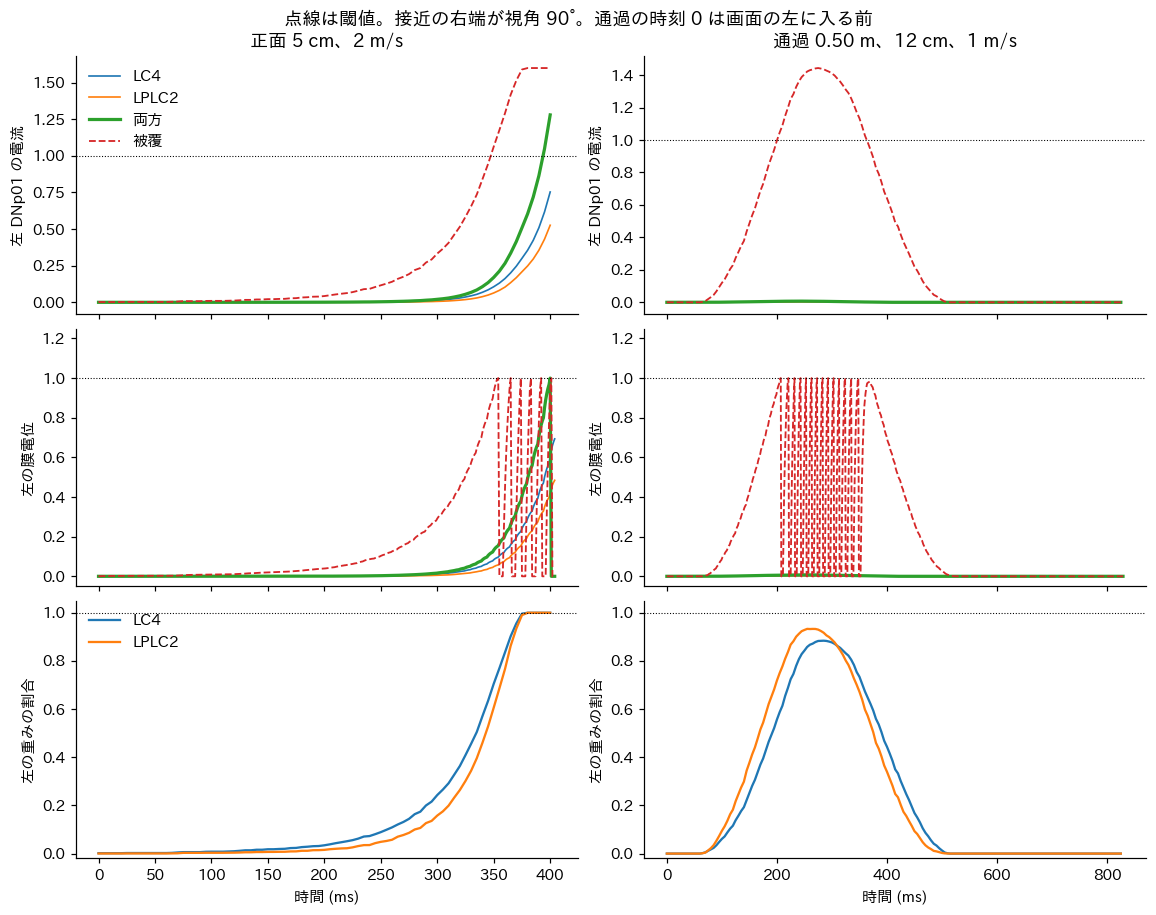

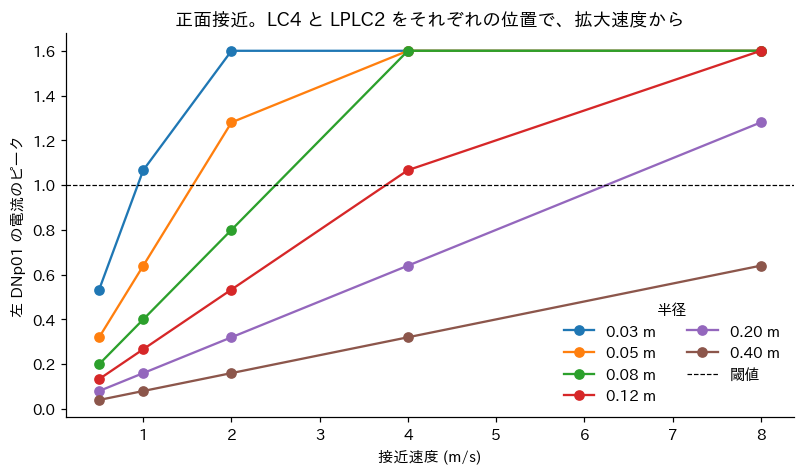

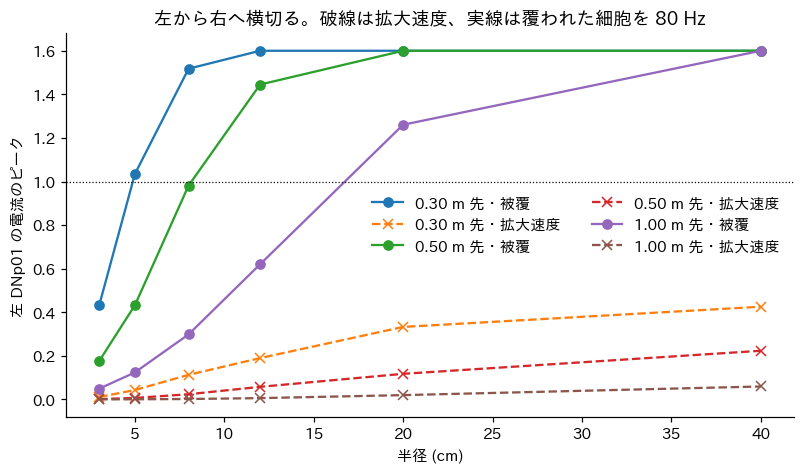

In [6]:
examples = []
for label, positions, velocity, radius in (
    ("正面 5 cm、2 m/s", *approach_path(0.05, 2.0, 0.0), 0.05),
    ("通過 0.50 m、12 cm、1 m/s", *passage_path(0.12, 1.0, 0.50), 0.12),
):
    summary, detail = simulate(positions, velocity, radius, keep=True)
    examples.append((label, summary, detail))
    print(
        f"{label}  視角 {summary['視角']:.0f}°  拡大速度 {summary['拡大速度']:.1f}  "
        f"割合差 {summary['割合差']:.3f}  "
        f"LC4 {summary['LC4スパイク左']}  LPLC2 {summary['LPLC2スパイク左']}  "
        f"両方 {summary['両方スパイク左']}/{summary['両方スパイク右']}  "
        f"被覆 {summary['被覆スパイク左']}/{summary['被覆スパイク右']}"
    )

fig, axes = plt.subplots(3, 2, figsize=(10.4, 8.0), sharex="col", constrained_layout=True)
styles = (("LC4", 1.1, "-"), ("LPLC2", 1.1, "-"), ("両方", 2.1, "-"), ("被覆", 1.2, "--"))
for column, (label, summary, detail) in enumerate(examples):
    time_ms = detail["geom_time"] * 1000
    membrane_ms = detail["time"] * 1000
    for name, width, linestyle in styles:
        axes[0, column].plot(time_ms, detail["current"][name][:, 0], lw=width, ls=linestyle, label=name)
        axes[1, column].plot(membrane_ms, detail["voltage"][name][:, 0], lw=width, ls=linestyle, label=name)
    axes[2, column].plot(time_ms, detail["share_lc4"][:, 0], label="LC4")
    axes[2, column].plot(time_ms, detail["share_lplc"][:, 0], label="LPLC2")
    for row in range(3):
        axes[row, column].axhline(1.0, color="k", lw=0.7, ls=":")
        axes[row, column].spines["top"].set_visible(False)
        axes[row, column].spines["right"].set_visible(False)
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel("左 DNp01 の電流")
    axes[1, column].set_ylabel("左の膜電位")
    axes[1, column].set_ylim(-0.05, 1.25)
    axes[2, column].set_ylabel("左の重みの割合")
    axes[2, column].set_xlabel("時間 (ms)")
    axes[2, column].set_ylim(-0.02, 1.05)
axes[0, 0].legend(frameon=False, loc="upper left")
axes[2, 0].legend(frameon=False, loc="upper left")
fig.suptitle("点線は閾値。接近の右端が視角 90°。通過の時刻 0 は画面の左に入る前", y=1.02)
plt.show()

front_plot = approach.loc[approach["経路"].eq("正面")]
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
for radius, part in front_plot.groupby("半径"):
    ax.plot(part["速度"], part["両方電流左"], marker="o", label=f"{radius:.2f} m")
ax.axhline(1.0, color="k", lw=0.8, ls="--", label="閾値")
ax.set_xlabel("接近速度 (m/s)")
ax.set_ylabel("左 DNp01 の電流のピーク")
ax.set_title("正面接近。LC4 と LPLC2 をそれぞれの位置で、拡大速度から")
ax.legend(frameon=False, title="半径", ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
for distance, part in peak.groupby("距離"):
    ax.plot(part["半径"] * 100, part["被覆電流"], marker="o", label=f"{distance:.2f} m 先・被覆")
    ax.plot(part["半径"] * 100, part["両方電流"], marker="x", ls="--", label=f"{distance:.2f} m 先・拡大速度")
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("半径 (cm)")
ax.set_ylabel("左 DNp01 の電流のピーク")
ax.set_title("左から右へ横切る。破線は拡大速度、実線は覆われた細胞を 80 Hz")
ax.legend(frameon=False, ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## 読み方

片眼を全部 80 Hz にすると、電流は LC4 だけが左 0.942、右 0.860、LPLC2 だけが左 0.658、右 0.740 である。どちらも 1 に届かない。両方で 1.600 になる。試した接近と通過のすべてで、LC4 だけ、または LPLC2 だけを拡大速度で駆動したスパイクは 0 だった。閾値を超えるには、今の定数では両方の入力が要る。

正面接近では、接触の直前に画面が両方の細胞種で埋まる。そのピーク電流は、LPLC2 に LC4 と同じ割合を入れたときと一致する。発火するのは、接触直前の拡大速度が 40 rad/s 以上のときで、その値は速度/半径である。半径 3 cm は 2 m/s から、半径 5 cm は 2 m/s から、半径 8 cm は 4 m/s から、半径 12 cm は 8 m/s、半径 20 cm は 8 m/s。半径 40 cm は 8 m/s でも 20 rad/s、電流 0.64 で届かない。拡大速度 33 rad/s（半径 3 cm の 1 m/s と、半径 12 cm の 4 m/s）は電流 1.067 だが、閾値を超えている時間が短く、スパイクは 0 だった。40 rad/s、電流 1.28 では 1 回出る。回数は、電流が 1 を超えている長さで 1 回か 2 回になる。速いほど多いわけではない。

割合の差は、画面が埋まる前に最大 0.16 ほど開く。正面で、この差がスパイクの有無を変えた行は無い。半径 5 cm の 8 m/s だけ回数が違う。接触の 10 ms 前に LC4 の割合が 0.84、LPLC2 が 0.77 で、同じ割合の電流は 1.10、位置を分けた両方は 1.07 になる。同じ割合は左右 2 回、位置を分けた両方は左右 1 回だった。

左右に 0.15 m ずらすと、球は水平 52° の画角から外れる。拡大速度は最大 25 rad/s ほどで、両方の電流は 0.80 を超えず、スパイクは 0 だった。被覆では半径 12 cm 以上で近い側が発火し、半径 40 cm は両側が発火する。左からの接近は左の DNp01、右からは右である。0.5 m/s から 8 m/s までこの分かれ方は残る。右の発火から左の発火を引くヨーは、物体から離れる向きになる。

通過は拡大速度が最大 13.3 rad/s（半径 40 cm、0.30 m 先、8 m/s）で、拡大速度の電流は 0.43 を超えず、スパイクは 0 だった。

被覆では LPLC2 の割合が LC4 より高い。0.30 m 先の半径 5 cm は、LC4 の割合 0.62 だけなら電流が約 1.00 で膜が届かない大きさである。LPLC2 の割合 0.69 を足すと、電流は左 1.035、右 1.031 になる。0.5 m/s では左右とも 2 回発火し、2 m/s では左だけ 1 回、8 m/s では通り過ぎが速く 0 回だった。半径 3 cm は電流 0.43 で、どの速度でも 0 回。半径 8 cm は電流 1.51 で、8 m/s でも発火する。0.50 m 先は半径 8 cm が電流 0.98 で 0 回、半径 12 cm は 1.44 で 8 m/s でも発火する。1.0 m 先は半径 12 cm が 0.62 で 0 回、半径 20 cm が 1.26 で発火する。

静止した半径 0.10 の円を左の中央に置くと、LC4 の割合は 0.132、LPLC2 は 0.161 で、右は 0 のままである。80 Hz にしても電流は 0.231 で、閾値の下である。

画面が埋まる正面の境界は、割合を細胞種で分けても前と同じ 40 rad/s である。位置を分けた効果は、円が片眼の一部だけを覆うときに出る。通過の被覆では、0.30 m 先の半径 5 cm が、遅い横断に限って閾値を超える。
